<h1>Transformer Text Generator</h1>

<h2>1. Business understanding</h2>

The goal of this project is to build a text generator using a Transformer model. The model will be trained on Sherlock Holmes text from Project Gutenberg.

The aim is to understand how a Transformer learns from text and how different model settings affect the quality of generated text.

<h2>2. Data understanding</h2>

The dataset consists of the book `The case-book of Sherlock Holmes by Arthur Conan Doyle`, which was downloaded from [Project Gutenberg](https://www.gutenberg.org/). The dataset contains English language stories about Sherlock Holmes and provides the material for training the text generation model.
  - Book name: The Case-Book of Sherlock Holmes
  - Author: Arthur Conan Doyle
  - Language: English
  - Source: Project Gutenberg
  - Original data size: 472.33 KB
  - Original text lenght: 473,158 characters
  - Cleaned data size: 443.14 KB
  - Cleaned text lenght: 453,762 characters

In [18]:
import os

import numpy as np
import keras
import sentencepiece as spm
import matplotlib.pyplot as plt
import time #for measuring model training time

# set a random seed for reproducibility (results are reproducible when the whole notebook 
# is run from top to bottom)
seed = 54
keras.utils.set_random_seed(seed)

print(f"Keras version: {keras.__version__}")
print(f"Keras backend: {keras.config.backend()}")

Keras version: 3.15.1
Keras backend: tensorflow


We start by loading the data and checking it's size.

In [19]:
file_path = "./txt/The_Project_Gutenberg.txt"
size_bytes = os.path.getsize(file_path)

with open(file_path, 'r', encoding='utf-8-sig') as file: # load the project gutenberg text
    text = file.read()

print(f"Text length: {len(text)} characters")
print(f'File size: {round(size_bytes / 1024, 2)} KB')
print(f"First 100 characters: {text[:100]}")

Text length: 473158 characters
File size: 472.33 KB
First 100 characters: The Project Gutenberg eBook of The case-book of Sherlock Holmes
    
This eBook is for the use of an


After loading the data, we see that the dataset length consist of `473,158 characters`. Note that this contains the license texts before and after the actual e-book. The file size is `472.33 KB`. The first 100 characters show the beginning of the book.

<h2>3. Data preparation</h2>

The code trains a SentencePiece tokenizer using the Gutenberg text dataset with the Byte Pair Encoding algorithm. The goal is to create a BPE based tokenizer trained on Gutenberg text that splits text into smaller, reusable token units. Each token is assigned a numerical ID. These IDs are used as input to the Transformer model.

License text from the beginning and end is removed. The original full text is saved into `text` variable, and the clean text without license text into `clean_text`. The `clean_text` contains 453,762 characters.

In [20]:
# remove license text from the beginning and end
start = text.find("*** START OF")
start = text.find("\n", start) + 1
end = text.find("*** END OF")
clean_text = text[start:end]
clean_size_bytes = len(clean_text.encode("utf-8"))
print("Original text lenght:", len(text), "\nLength after license texts removed:", len(clean_text))
print(f"Clean text size: {clean_size_bytes / 1024:.2f} KB")

Original text lenght: 473158 
Length after license texts removed: 453762
Clean text size: 443.14 KB


Next we create tokenizer using the clean_text. It will then be used for training our models.

Finally, the trained tokenizer is loaded and tested by tokenizing the sentence "It was from the Carlton Club". The code prints the resulting tokens and the actual vocabulary size.

Next we prepare the tokenized Gutenberg text for training a language model.

### Clean tokenizer without the license text
The tokenizer uses the `clean_text`, which does not have the license text. The trained SentencePiece tokenizer is saved into `sp_clean`, which uses prefix `gutenberg_sp_clean`. 

In [21]:
# train SentencePiece model on the cleaned text (license text removed)
# save clean text to a temporary file for SentencePiece training

temp_file_clean = 'gutenberg_temp_clean.txt'
with open(temp_file_clean, 'w', encoding='utf-8') as f:
    f.write(clean_text)

# train SentencePiece model
vocab_size = 2000
model_prefix_clean = 'gutenberg_sp_clean'  # separate prefix so the first tokenizer is not overwritten

spm.SentencePieceTrainer.train(
    input=temp_file_clean,
    model_prefix=model_prefix_clean,
    vocab_size=vocab_size,
    character_coverage=1.0,
    model_type='bpe',
    user_defined_symbols=['<PAD>', '<UNK>']
)

# load the trained tokenizer
sp_clean = spm.SentencePieceProcessor()
sp_clean.load(f"{model_prefix_clean}.model")

# test tokenization
test_text = "It was from the Carlton Club"
tokens = sp_clean.encode_as_pieces(test_text)

print(f"Tokenized example: {tokens}")
print(f"Vocabulary size: {sp_clean.get_piece_size()}")

Tokenized example: ['▁It', '▁was', '▁from', '▁the', '▁C', 'ar', 'lt', 'on', '▁C', 'l', 'ub']
Vocabulary size: 2000


The trained tokenizer is loaded and tested by tokenizing the sentence "It was from the Carlton Club". The code prints the resulting tokens and the actual vocabulary size.

Next we prepare the tokenized clean text for training a language model.

In [22]:
# prepare training data from the cleaned text

seq_length = 64
pieces_clean = sp_clean.encode_as_ids(clean_text)
print(f"Total tokens: {len(pieces_clean)}")

sequences_clean = []
for i in range(0, len(pieces_clean) - seq_length):
    sequences_clean.append(pieces_clean[i:i+seq_length+1])

sequences_clean = np.array(sequences_clean)
inputs_clean = sequences_clean[:, :-1]
targets_clean = sequences_clean[:, 1:]

print(f"Number of sequences: {len(sequences_clean)}")
print(f"Input shape: {inputs_clean.shape}")
print(f"Target shape: {targets_clean.shape}")

# 90 % train / 10 % validation, skipping seq_length sequences at the boundary
split_clean = int(0.9 * len(sequences_clean))
train_inputs_clean = inputs_clean[:split_clean]
train_targets_clean = targets_clean[:split_clean]
val_inputs_clean = inputs_clean[split_clean + seq_length:]
val_targets_clean = targets_clean[split_clean + seq_length:]

Total tokens: 132112
Number of sequences: 132048
Input shape: (132048, 64)
Target shape: (132048, 64)


The output displays the informaton about our training data. We can see, that the total amount of tokens createt is `132112`

<h2>4. Modeling</h2>

Now we train 4 different models, and inspect how different parameters affect each models training time and quality.

Every model uses `EarlyStopping`, where `patience is 3`.

### Model 1

Here we start by building a small Transformer-based language model that learns to predict the next token in a sequence. The model is stored as `model_clean`.

In [23]:
# define the models, done once
def get_positional_encoding(max_len, d_model):
    """Create sinusoidal positional encoding."""
    positions = np.arange(max_len)[:, np.newaxis]
    angles = np.arange(d_model)[np.newaxis, :] / d_model
    angles = 1 / (10000**angles)

    pos_encoding = positions * angles
    pos_encoding[:, 0::2] = np.sin(pos_encoding[:, 0::2])
    pos_encoding[:, 1::2] = np.cos(pos_encoding[:, 1::2])

    return pos_encoding

In [24]:
# define model parameters
embed_dim = 64
num_heads = 2
ff_dim = 128
num_layers = 2

# create the model
inputs_clean_layer = keras.Input(shape=(seq_length,))
embedding_layer = keras.layers.Embedding(sp_clean.get_piece_size(), embed_dim)(inputs_clean_layer)

# add positional encoding
pos_encoding = get_positional_encoding(seq_length, embed_dim)
x = embedding_layer + pos_encoding

# transformer blocks
for _ in range(num_layers):
    attention_output = keras.layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embed_dim // num_heads,
        dropout=0.1
    )(x, x, use_causal_mask=True)
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + attention_output)

    ffn = keras.Sequential([
        keras.layers.Dense(ff_dim, activation="relu"),
        keras.layers.Dense(embed_dim),
        keras.layers.Dropout(0.1)
    ])
    ffn_output = ffn(x)
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + ffn_output)

# final output layer
outputs_clean = keras.layers.Dense(sp_clean.get_piece_size())(x)

model_clean = keras.Model(inputs=inputs_clean_layer, outputs=outputs_clean)

model_clean.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

model_clean.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)    │ (None, 64)                │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ embedding_2 (Embedding)       │ (None, 64, 64)            │         128,000 │ input_layer_4[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_5 (Add)                   │ (None, 64, 64)            │               0 │ embedding_2[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multi_head_attention_2        │ (None, 64, 64)            │          16,640 │ add_5[0][0], add_5[0][0]   │
│ (MultiHeadAttention)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_6 (Add)                   │ (None, 64, 64)            │               0 │ add_5[0][0],               │
│                               │                           │                 │ multi_head_attention_2[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layer_normalization_4         │ (None, 64, 64)            │             128 │ add_6[0][0]                │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ sequential_2 (Sequential)     │ (None, 64, 64)            │          16,576 │ layer_normalization_4[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_7 (Add)                   │ (None, 64, 64)            │               0 │ layer_normalization_4[0][… │
│                               │                           │                 │ sequential_2[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layer_normalization_5         │ (None, 64, 64)            │             128 │ add_7[0][0]                │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multi_head_attention_3        │ (None, 64, 64)            │          16,640 │ layer_normalization_5[0][… │
│ (MultiHeadAttention)          │                           │                 │ layer_normalization_5[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_8 (Add)                   │ (None, 64, 64)            │               0 │ layer_normalization_5[0][… │
│                               │                           │                 │ multi_head_attention_3[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layer_normalization_6         │ (None, 64, 64)            │             128 │ add_8[0][0]                │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ sequential_3 (Sequential)     │ (None, 64, 64)            │          16,576 │ layer_normalization_6[0][… │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 324,944 (1.24 MB)

 Trainable params: 324,944 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

After the models parameters are defined, we move on training the model. The history is saved as `history_01`.

In [25]:
batch_size = 32
epochs = 30

start_time = time.perf_counter()

history_01 = model_clean.fit(
    train_inputs_clean, train_targets_clean,
    validation_data=(val_inputs_clean, val_targets_clean),
    batch_size=batch_size,
    epochs=epochs,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=1),
        keras.callbacks.ModelCheckpoint('gutenberg_best_model_clean.keras', save_best_only=True)
    ]
)

training_time = time.perf_counter() - start_time

print(f"Training time: {training_time:.2f} seconds")

Epoch 1/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 228s 59ms/step - accuracy: 0.1496 - loss: 4.8221 - val_accuracy: 0.1635 - val_loss: 4.6296 - learning_rate: 3.0000e-04
Epoch 2/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 228s 61ms/step - accuracy: 0.2233 - loss: 3.8007 - val_accuracy: 0.1797 - val_loss: 4.6598 - learning_rate: 3.0000e-04
Epoch 3/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 236s 64ms/step - accuracy: 0.2576 - loss: 3.4877 - val_accuracy: 0.1826 - val_loss: 4.7351 - learning_rate: 1.5000e-04
Epoch 4/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 279s 68ms/step - accuracy: 0.2732 - loss: 3.3628 - val_accuracy: 0.1830 - val_loss: 4.7863 - learning_rate: 7.5000e-05
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 1.
Training time: 971.61 seconds


`EarlyStopping` measures `val_loss` as default and saves the best model based on the best `val_loss` value.

We continue by plotting the training metrics and save the model as `gutenberg_model_clean.keras`.

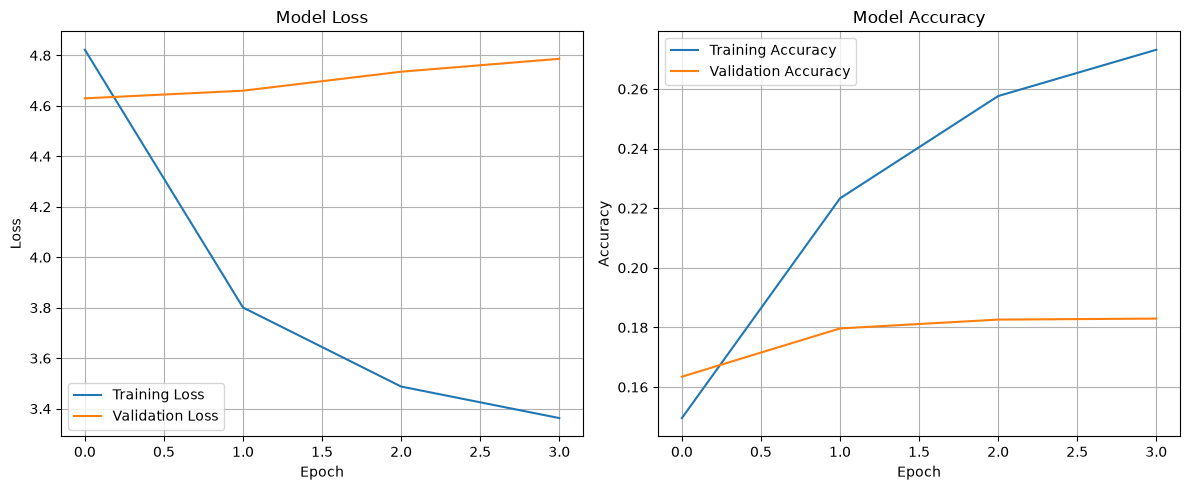

In [26]:
# function to plot training metrics, used by the models
def plot_training_metrics(history):
    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Training Loss')
    plt.plot(history.history['val_loss'], label='Validation Loss')
    plt.title('Model Loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.grid()
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], label='Training Accuracy')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
    plt.title('Model Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.grid()
    plt.legend()

    plt.tight_layout()
    plt.show()
    
plot_training_metrics(history_01)

# save the model
model_clean.save('gutenberg_model_clean_B.keras')

Now, let's generate text with the sample text (`prompt`). We use the number of tokens (100) and temperature (1.2).

In [27]:
def generate_text(model, sp, prompt, num_tokens=100, temperature=1.0): # generated once for all the models
    """
    Generate text autoregressively.

    Args:
        temperature: Controls randomness
            - Low (0.1-0.5): Focused, repetitive
            - Medium (0.7-1.0): Balanced
            - High (1.5+): Creative, chaotic
    """
    # Encode the prompt
    input_ids = sp.encode_as_ids(prompt)

    # Rest of your generation code stays the same...
    if len(input_ids) < seq_length:
        padding_length = seq_length - len(input_ids)
        input_ids = [0] * padding_length + input_ids
    else:
        padding_length = 0
        input_ids = input_ids[-seq_length:]

    # Generated tokens
    generated_ids = list(input_ids[padding_length:])

    # Generate text token by token
    for _ in range(num_tokens):
        x = np.array([input_ids])
        predictions = model.predict(x, verbose=0)[0]
        logits = predictions[-1]
        logits = logits / temperature
        exp_logits = np.exp(logits - np.max(logits))
        probs = exp_logits / np.sum(exp_logits)
        next_token = np.random.choice(len(probs), p=probs)
        generated_ids.append(next_token)
        input_ids = input_ids[1:] + [next_token]

    # Decode the generated sequence
    generated_text = sp.decode(generated_ids)

    return generated_text

In [28]:
# generate sample text (other models use "prompts" as well)
prompts = [
    "It was from the Carlton Club",
    "Have you ever heard of Baron Gruner?",
    "Then you will sympathize with the client",
    "Our visitor was greatly disturbed"
]

for prompt in prompts:
    print(f"\nPrompt: {prompt}")
    generated = generate_text(model_clean, sp_clean, prompt, num_tokens=100, temperature=1.2)
    print(generated)


Prompt: It was from the Carlton Club
It was from the Carlton Clubless brainness the famous diery heavld seong involves. Aate aw: "The do you tell it some tr ready upon the ess moment. You can get of some qu can deects saw what mean, in considering presentric. And the cursed man pecides theiled directors. Vish Pragriby Viican in her hands with the Austhestute person'tarth skinct." "

Prompt: Have you ever heard of Baron Gruner?
Have you ever heard of Baron Gruner? What, there you came would The askgether alone." "Not nothing of crime since you. I plled on. Mr. Ker cppger, soon arrived, that And us or that the ce of Wakening. That morning before you kindp which." It was rif by two serious st answered.ce his incident is hir since his ask." "I do not play this ladyile adver skesture very surge out of f

Prompt: Then you will sympathize with the client
Then you will sympathize with the client when there were greatly as her gocent behind her. Then if I hacept that regree by his whole hopy a

Let's print the training results from the best epoch.

In [29]:
# get the best epoch
best_epoch = int(np.argmin(history_01.history['val_loss']))
print(f"Best epoch: {best_epoch + 1}")

# print results
for key in ['loss', 'accuracy', 'val_loss', 'val_accuracy']:
    print(f"{key}: {history_01.history[key][best_epoch]:.4f}")

Best epoch: 1
loss: 4.8221
accuracy: 0.1496
val_loss: 4.6296
val_accuracy: 0.1635


The model is overfitted clearly overfitted. It has high value loss and low accuracy.

### Model 2
Let's try to reduce overfitting with a higher dropout value. The previous was 0.1, and now we try 0.3. Otherwise this model is same as the model 2. Let's save this model as `model_clean_dropout03`.

In [30]:
# define model parameters
embed_dim = 64
num_heads = 2
ff_dim = 128
num_layers = 2

# create the model
inputs_clean_layer = keras.Input(shape=(seq_length,))
embedding_layer = keras.layers.Embedding(sp_clean.get_piece_size(), embed_dim)(inputs_clean_layer)

# add positional encoding
pos_encoding = get_positional_encoding(seq_length, embed_dim)
x = embedding_layer + pos_encoding

# transformer blocks
for _ in range(num_layers):
    attention_output = keras.layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embed_dim // num_heads,
        dropout=0.3
    )(x, x, use_causal_mask=True)
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + attention_output)

    ffn = keras.Sequential([
        keras.layers.Dense(ff_dim, activation="relu"),
        keras.layers.Dense(embed_dim),
        keras.layers.Dropout(0.3)
    ])
    ffn_output = ffn(x)
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + ffn_output)

# final output layer
outputs_clean = keras.layers.Dense(sp_clean.get_piece_size())(x)

model_clean_dropout03 = keras.Model(inputs=inputs_clean_layer, outputs=outputs_clean)

model_clean_dropout03.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

model_clean_dropout03.summary()

Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_7 (InputLayer)    │ (None, 64)                │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ embedding_3 (Embedding)       │ (None, 64, 64)            │         128,000 │ input_layer_7[0][0]        │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_10 (Add)                  │ (None, 64, 64)            │               0 │ embedding_3[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multi_head_attention_4        │ (None, 64, 64)            │          16,640 │ add_10[0][0], add_10[0][0] │
│ (MultiHeadAttention)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_11 (Add)                  │ (None, 64, 64)            │               0 │ add_10[0][0],              │
│                               │                           │                 │ multi_head_attention_4[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layer_normalization_8         │ (None, 64, 64)            │             128 │ add_11[0][0]               │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ sequential_4 (Sequential)     │ (None, 64, 64)            │          16,576 │ layer_normalization_8[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_12 (Add)                  │ (None, 64, 64)            │               0 │ layer_normalization_8[0][… │
│                               │                           │                 │ sequential_4[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layer_normalization_9         │ (None, 64, 64)            │             128 │ add_12[0][0]               │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multi_head_attention_5        │ (None, 64, 64)            │          16,640 │ layer_normalization_9[0][… │
│ (MultiHeadAttention)          │                           │                 │ layer_normalization_9[0][… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_13 (Add)                  │ (None, 64, 64)            │               0 │ layer_normalization_9[0][… │
│                               │                           │                 │ multi_head_attention_5[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layer_normalization_10        │ (None, 64, 64)            │             128 │ add_13[0][0]               │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ sequential_5 (Sequential)     │ (None, 64, 64)            │          16,576 │ layer_normalization_10[0]… │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 324,944 (1.24 MB)

 Trainable params: 324,944 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 291s 76ms/step - accuracy: 0.1409 - loss: 4.9176 - val_accuracy: 0.1606 - val_loss: 4.6507 - learning_rate: 3.0000e-04
Epoch 2/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 267s 72ms/step - accuracy: 0.2091 - loss: 3.8610 - val_accuracy: 0.1755 - val_loss: 4.6569 - learning_rate: 3.0000e-04
Epoch 3/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 272s 73ms/step - accuracy: 0.2372 - loss: 3.5725 - val_accuracy: 0.1811 - val_loss: 4.7220 - learning_rate: 1.5000e-04
Epoch 4/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 262s 70ms/step - accuracy: 0.2498 - loss: 3.4635 - val_accuracy: 0.1833 - val_loss: 4.7627 - learning_rate: 7.5000e-05
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 1.


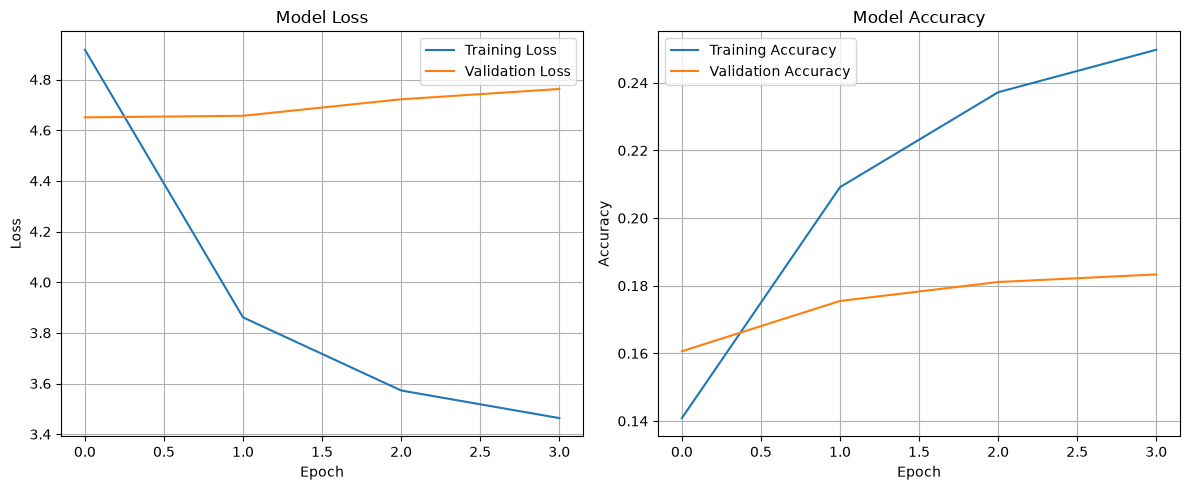

Best epoch: 1
loss: 4.9176
accuracy: 0.1409
val_loss: 4.6507
val_accuracy: 0.1606
Training time: 1091.06 seconds


In [31]:
# train
batch_size = 32
epochs = 30

start_time = time.perf_counter()

history_02 = model_clean_dropout03.fit(
    train_inputs_clean, train_targets_clean,
    validation_data=(val_inputs_clean, val_targets_clean),
    batch_size=batch_size,
    epochs=epochs,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=1),
        keras.callbacks.ModelCheckpoint('gutenberg_best_model_clean_dropout03.keras', save_best_only=True)
    ]
)

training_time = time.perf_counter() - start_time

# plot training results
plot_training_metrics(history_02)

# save the model
model_clean_dropout03.save('gutenberg_model_clean_dropout03.keras')

# get the best epoch
best_epoch = int(np.argmin(history_02.history['val_loss']))
print(f"Best epoch: {best_epoch + 1}")

# print results
for key in ['loss', 'accuracy', 'val_loss', 'val_accuracy']:
    print(f"{key}: {history_02.history[key][best_epoch]:.4f}")

print(f"Training time: {training_time:.2f} seconds")

### Model 3
Next, we try a smaller model. Let's change dropout back to 0.1. The model is saved as `model_clean_small`.

In [32]:
# define model parameters
embed_dim = 32
num_heads = 2
ff_dim = 64
num_layers = 1

# create the model
inputs_clean_layer = keras.Input(shape=(seq_length,))
embedding_layer = keras.layers.Embedding(sp_clean.get_piece_size(), embed_dim)(inputs_clean_layer)

# add positional encoding
pos_encoding = get_positional_encoding(seq_length, embed_dim)
x = embedding_layer + pos_encoding

# transformer blocks
for _ in range(num_layers):
    attention_output = keras.layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embed_dim // num_heads,
        dropout=0.1
    )(x, x, use_causal_mask=True)
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + attention_output)

    ffn = keras.Sequential([
        keras.layers.Dense(ff_dim, activation="relu"),
        keras.layers.Dense(embed_dim),
        keras.layers.Dropout(0.1)
    ])
    ffn_output = ffn(x)
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + ffn_output)

# final output layer
outputs_clean = keras.layers.Dense(sp_clean.get_piece_size())(x)

model_clean_small = keras.Model(inputs=inputs_clean_layer, outputs=outputs_clean)

model_clean_small.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

model_clean_small.summary()

Model: "functional_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)   │ (None, 64)                │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ embedding_4 (Embedding)       │ (None, 64, 32)            │          64,000 │ input_layer_10[0][0]       │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_15 (Add)                  │ (None, 64, 32)            │               0 │ embedding_4[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multi_head_attention_6        │ (None, 64, 32)            │           4,224 │ add_15[0][0], add_15[0][0] │
│ (MultiHeadAttention)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_16 (Add)                  │ (None, 64, 32)            │               0 │ add_15[0][0],              │
│                               │                           │                 │ multi_head_attention_6[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layer_normalization_12        │ (None, 64, 32)            │              64 │ add_16[0][0]               │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ sequential_6 (Sequential)     │ (None, 64, 32)            │           4,192 │ layer_normalization_12[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_17 (Add)                  │ (None, 64, 32)            │               0 │ layer_normalization_12[0]… │
│                               │                           │                 │ sequential_6[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layer_normalization_13        │ (None, 64, 32)            │              64 │ add_17[0][0]               │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ dense_17 (Dense)              │ (None, 64, 2000)          │          66,000 │ layer_normalization_13[0]… │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 138,544 (541.19 KB)

 Trainable params: 138,544 (541.19 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 184s 48ms/step - accuracy: 0.1286 - loss: 5.1316 - val_accuracy: 0.1461 - val_loss: 4.8205 - learning_rate: 3.0000e-04
Epoch 2/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 177s 48ms/step - accuracy: 0.1819 - loss: 4.2209 - val_accuracy: 0.1553 - val_loss: 4.7411 - learning_rate: 3.0000e-04
Epoch 3/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 200s 47ms/step - accuracy: 0.1926 - loss: 4.0360 - val_accuracy: 0.1605 - val_loss: 4.7568 - learning_rate: 3.0000e-04
Epoch 4/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 175s 47ms/step - accuracy: 0.1997 - loss: 3.9511 - val_accuracy: 0.1619 - val_loss: 4.7683 - learning_rate: 1.5000e-04
Epoch 5/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 175s 47ms/step - accuracy: 0.2031 - loss: 3.9159 - val_accuracy: 0.1628 - val_loss: 4.7732 - learning_rate: 7.5000e-05
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 2.


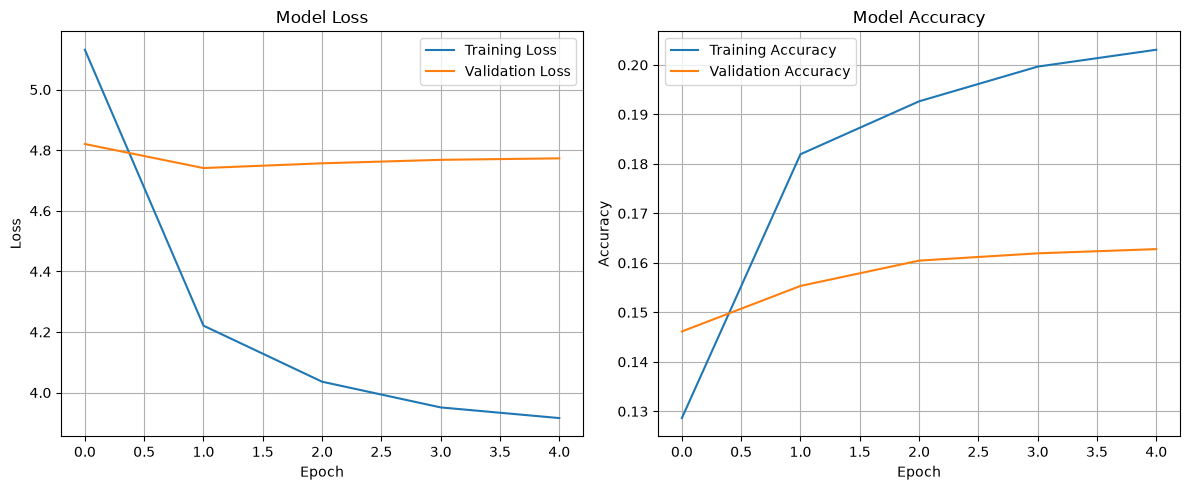

Best epoch: 2
loss: 4.2209
accuracy: 0.1819
val_loss: 4.7411
val_accuracy: 0.1553
Training time: 911.63 seconds


In [33]:
# train
batch_size = 32
epochs = 30

start_time = time.perf_counter()

history_03 = model_clean_small.fit(
    train_inputs_clean, train_targets_clean,
    validation_data=(val_inputs_clean, val_targets_clean),
    batch_size=batch_size,
    epochs=epochs,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=1),
        keras.callbacks.ModelCheckpoint('gutenberg_best_model_clean_small.keras', save_best_only=True)
    ]
)

training_time = time.perf_counter() - start_time

# plot training results
plot_training_metrics(history_03)

# save the model
model_clean_small.save('gutenberg_model_clean_small.keras')

# get the best epoch
best_epoch = int(np.argmin(history_03.history['val_loss']))
print(f"Best epoch: {best_epoch + 1}")

# print results
for key in ['loss', 'accuracy', 'val_loss', 'val_accuracy']:
    print(f"{key}: {history_03.history[key][best_epoch]:.4f}")

print(f"Training time: {training_time:.2f} seconds")

### Model 4
Next, we try a model with a smaller vocabulary (1000). New tokenizer is created.

In [34]:
# tokenizer with vocab size 1000, trained on the clean text
temp_file_clean = 'gutenberg_temp_clean.txt'
with open(temp_file_clean, 'w', encoding='utf-8') as f:
    f.write(clean_text)

vocab_size_v1000 = 1000
model_prefix_v1000 = 'gutenberg_sp_v1000'

spm.SentencePieceTrainer.train(
    input=temp_file_clean,
    model_prefix=model_prefix_v1000,
    vocab_size=vocab_size_v1000,
    character_coverage=1.0,
    model_type='bpe',
    user_defined_symbols=['<PAD>', '<UNK>']
)

sp_v1000 = spm.SentencePieceProcessor()
sp_v1000.load(f"{model_prefix_v1000}.model")

tokens = sp_v1000.encode_as_pieces("It was from the Carlton Club")
print(f"Tokenized example: {tokens}")
print(f"Vocabulary size: {sp_v1000.get_piece_size()}")

Tokenized example: ['▁It', '▁was', '▁from', '▁the', '▁C', 'ar', 'l', 't', 'on', '▁C', 'l', 'ub']
Vocabulary size: 1000


Then we prepare the training data.

In [35]:
# prepare training data with the 1000-token vocabulary
pieces_v1000 = sp_v1000.encode_as_ids(clean_text)
print(f"Total tokens: {len(pieces_v1000)}")

sequences_v1000 = []
for i in range(0, len(pieces_v1000) - seq_length):
    sequences_v1000.append(pieces_v1000[i:i + seq_length + 1])

sequences_v1000 = np.array(sequences_v1000)
inputs_v1000 = sequences_v1000[:, :-1]
targets_v1000 = sequences_v1000[:, 1:]

print(f"Number of sequences: {len(sequences_v1000)}")
print(f"Input shape: {inputs_v1000.shape}")

# 90 % train / 10 % validation
split_v1000 = int(0.9 * len(sequences_v1000))
train_inputs_v1000 = inputs_v1000[:split_v1000]
train_targets_v1000 = targets_v1000[:split_v1000]
val_inputs_v1000 = inputs_v1000[split_v1000 + seq_length:]
val_targets_v1000 = targets_v1000[split_v1000 + seq_length:]

Total tokens: 153183
Number of sequences: 153119
Input shape: (153119, 64)


Next, we create the model.

In [36]:
# define model parameters (same as model 2)
embed_dim = 64
num_heads = 2
ff_dim = 128
num_layers = 2

# create the model
inputs_v1000_layer = keras.Input(shape=(seq_length,))
embedding_layer = keras.layers.Embedding(sp_v1000.get_piece_size(), embed_dim)(inputs_v1000_layer)

# add positional encoding
pos_encoding = get_positional_encoding(seq_length, embed_dim)
x = embedding_layer + pos_encoding

# transformer blocks
for _ in range(num_layers):
    attention_output = keras.layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embed_dim // num_heads,
        dropout=0.1
    )(x, x, use_causal_mask=True)
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + attention_output)

    ffn = keras.Sequential([
        keras.layers.Dense(ff_dim, activation="relu"),
        keras.layers.Dense(embed_dim),
        keras.layers.Dropout(0.1)
    ])
    ffn_output = ffn(x)
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + ffn_output)

# final output layer
outputs_v1000 = keras.layers.Dense(sp_v1000.get_piece_size())(x)

model_clean_v1000 = keras.Model(inputs=inputs_v1000_layer, outputs=outputs_v1000)

model_clean_v1000.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

model_clean_v1000.summary()

Model: "functional_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_12 (InputLayer)   │ (None, 64)                │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ embedding_5 (Embedding)       │ (None, 64, 64)            │          64,000 │ input_layer_12[0][0]       │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_18 (Add)                  │ (None, 64, 64)            │               0 │ embedding_5[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multi_head_attention_7        │ (None, 64, 64)            │          16,640 │ add_18[0][0], add_18[0][0] │
│ (MultiHeadAttention)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_19 (Add)                  │ (None, 64, 64)            │               0 │ add_18[0][0],              │
│                               │                           │                 │ multi_head_attention_7[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layer_normalization_14        │ (None, 64, 64)            │             128 │ add_19[0][0]               │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ sequential_7 (Sequential)     │ (None, 64, 64)            │          16,576 │ layer_normalization_14[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_20 (Add)                  │ (None, 64, 64)            │               0 │ layer_normalization_14[0]… │
│                               │                           │                 │ sequential_7[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layer_normalization_15        │ (None, 64, 64)            │             128 │ add_20[0][0]               │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multi_head_attention_8        │ (None, 64, 64)            │          16,640 │ layer_normalization_15[0]… │
│ (MultiHeadAttention)          │                           │                 │ layer_normalization_15[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_21 (Add)                  │ (None, 64, 64)            │               0 │ layer_normalization_15[0]… │
│                               │                           │                 │ multi_head_attention_8[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layer_normalization_16        │ (None, 64, 64)            │             128 │ add_21[0][0]               │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ sequential_8 (Sequential)     │ (None, 64, 64)            │          16,576 │ layer_normalization_16[0]… │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 195,944 (765.41 KB)

 Trainable params: 195,944 (765.41 KB)

 Non-trainable params: 0 (0.00 B)

Let's train it.

In [37]:
batch_size = 32
epochs = 30

start_time = time.perf_counter()

history_04 = model_clean_v1000.fit(
    train_inputs_v1000, train_targets_v1000,
    validation_data=(val_inputs_v1000, val_targets_v1000),
    batch_size=batch_size,
    epochs=epochs,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=1),
        keras.callbacks.ModelCheckpoint('gutenberg_best_model_clean_v1000.keras', save_best_only=True)
    ]
)

training_time = time.perf_counter() - start_time

Epoch 1/30
4307/4307 ━━━━━━━━━━━━━━━━━━━━ 225s 51ms/step - accuracy: 0.1535 - loss: 4.4072 - val_accuracy: 0.1785 - val_loss: 4.1572 - learning_rate: 3.0000e-04
Epoch 2/30
4307/4307 ━━━━━━━━━━━━━━━━━━━━ 214s 50ms/step - accuracy: 0.2285 - loss: 3.6190 - val_accuracy: 0.2100 - val_loss: 4.0914 - learning_rate: 3.0000e-04
Epoch 3/30
4307/4307 ━━━━━━━━━━━━━━━━━━━━ 214s 50ms/step - accuracy: 0.2634 - loss: 3.3770 - val_accuracy: 0.2196 - val_loss: 4.1290 - learning_rate: 3.0000e-04
Epoch 4/30
4307/4307 ━━━━━━━━━━━━━━━━━━━━ 213s 49ms/step - accuracy: 0.2825 - loss: 3.2498 - val_accuracy: 0.2235 - val_loss: 4.1495 - learning_rate: 1.5000e-04
Epoch 5/30
4307/4307 ━━━━━━━━━━━━━━━━━━━━ 213s 49ms/step - accuracy: 0.2906 - loss: 3.1960 - val_accuracy: 0.2247 - val_loss: 4.1610 - learning_rate: 7.5000e-05
Epoch 5: early stopping
Restoring model weights from the end of the best epoch: 2.


The training metrics:

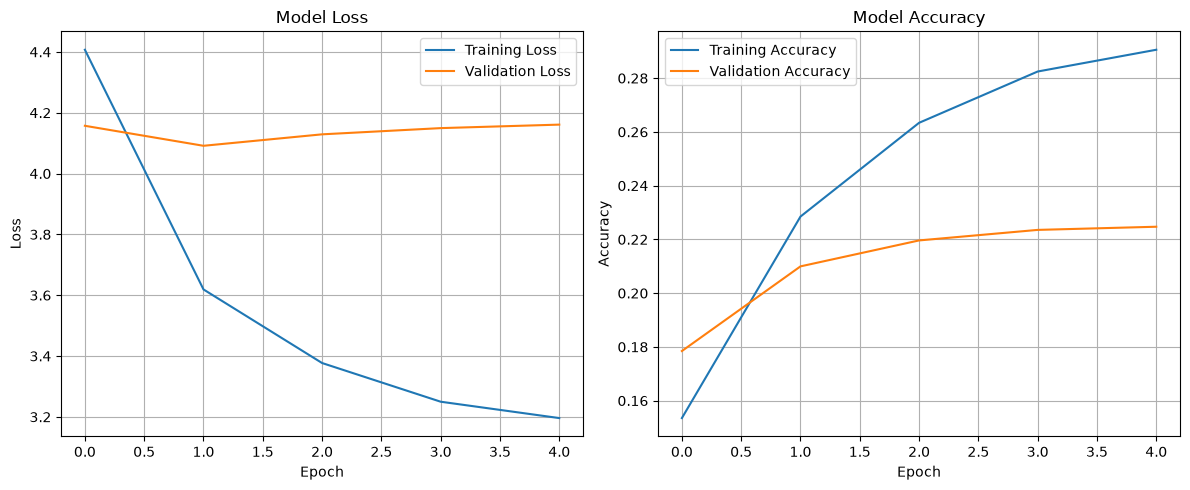

Best epoch: 2
loss: 3.6190
accuracy: 0.2285
val_loss: 4.0914
val_accuracy: 0.2100
Training time: 1078.77 seconds


In [38]:
plot_training_metrics(history_04)

model_clean_v1000.save('gutenberg_model_clean_v1000.keras')

best_epoch = int(np.argmin(history_04.history['val_loss']))
print(f"Best epoch: {best_epoch + 1}")
for key in ['loss', 'accuracy', 'val_loss', 'val_accuracy']:
    print(f"{key}: {history_04.history[key][best_epoch]:.4f}")

print(f"Training time: {training_time:.2f} seconds")

The model achieved a validation loss of 4.0582, which is the lowest of all the four models. However, this model has a smaller vocabulary of 1,000 tokens compared to the other models (2,000 tokens). Thus, model 4 is not straight compatible with other models.  

Validation loss measures the prediction error per one token. Different vocabulary sizes might result in different tokenizations of the same text, and the average length per token might be different. So, a lower validation loss might not necessarily mean that model 4 is better than the other models.

## Model 5

In [41]:
# define model parameters
embed_dim = 128
num_heads = 4
ff_dim = 256
num_layers = 3

# create the model
inputs_clean_layer = keras.Input(shape=(seq_length,))
embedding_layer = keras.layers.Embedding(sp_clean.get_piece_size(), embed_dim)(inputs_clean_layer)

# add positional encoding
pos_encoding = get_positional_encoding(seq_length, embed_dim)
x = embedding_layer + pos_encoding

# transformer blocks
for _ in range(num_layers):
    attention_output = keras.layers.MultiHeadAttention(
        num_heads=num_heads,
        key_dim=embed_dim // num_heads,
        dropout=0.1
    )(x, x, use_causal_mask=True)
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + attention_output)

    ffn = keras.Sequential([
        keras.layers.Dense(ff_dim, activation="relu"),
        keras.layers.Dense(embed_dim),
        keras.layers.Dropout(0.1)
    ])
    ffn_output = ffn(x)
    x = keras.layers.LayerNormalization(epsilon=1e-6)(x + ffn_output)

# final output layer
outputs_clean = keras.layers.Dense(sp_clean.get_piece_size())(x)

model_clean_big = keras.Model(inputs=inputs_clean_layer, outputs=outputs_clean)

model_clean_big.compile(
    optimizer=keras.optimizers.Adam(learning_rate=3e-4),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

model_clean_big.summary()

Model: "functional_17"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer_15 (InputLayer)   │ (None, 64)                │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ embedding_6 (Embedding)       │ (None, 64, 128)           │         256,000 │ input_layer_15[0][0]       │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_23 (Add)                  │ (None, 64, 128)           │               0 │ embedding_6[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multi_head_attention_9        │ (None, 64, 128)           │          66,048 │ add_23[0][0], add_23[0][0] │
│ (MultiHeadAttention)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_24 (Add)                  │ (None, 64, 128)           │               0 │ add_23[0][0],              │
│                               │                           │                 │ multi_head_attention_9[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layer_normalization_18        │ (None, 64, 128)           │             256 │ add_24[0][0]               │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ sequential_9 (Sequential)     │ (None, 64, 128)           │          65,920 │ layer_normalization_18[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_25 (Add)                  │ (None, 64, 128)           │               0 │ layer_normalization_18[0]… │
│                               │                           │                 │ sequential_9[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layer_normalization_19        │ (None, 64, 128)           │             256 │ add_25[0][0]               │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ multi_head_attention_10       │ (None, 64, 128)           │          66,048 │ layer_normalization_19[0]… │
│ (MultiHeadAttention)          │                           │                 │ layer_normalization_19[0]… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ add_26 (Add)                  │ (None, 64, 128)           │               0 │ layer_normalization_19[0]… │
│                               │                           │                 │ multi_head_attention_10[0… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ layer_normalization_20        │ (None, 64, 128)           │             256 │ add_26[0][0]               │
│ (LayerNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ sequential_10 (Sequential)    │ (None, 64, 128)           │          65,920 │ layer_normalization_20[0]… │
├───────────────────────────────┼───────────────────────────┼───────────────

 Total params: 911,440 (3.48 MB)

 Trainable params: 911,440 (3.48 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 562s 149ms/step - accuracy: 0.1812 - loss: 4.4288 - val_accuracy: 0.1863 - val_loss: 4.5361 - learning_rate: 3.0000e-04
Epoch 2/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 455s 123ms/step - accuracy: 0.3245 - loss: 3.0267 - val_accuracy: 0.1832 - val_loss: 5.1193 - learning_rate: 3.0000e-04
Epoch 3/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 440s 118ms/step - accuracy: 0.4378 - loss: 2.3390 - val_accuracy: 0.1750 - val_loss: 5.5883 - learning_rate: 1.5000e-04
Epoch 4/30
3714/3714 ━━━━━━━━━━━━━━━━━━━━ 440s 118ms/step - accuracy: 0.4949 - loss: 2.0432 - val_accuracy: 0.1727 - val_loss: 5.8491 - learning_rate: 7.5000e-05
Epoch 4: early stopping
Restoring model weights from the end of the best epoch: 1.


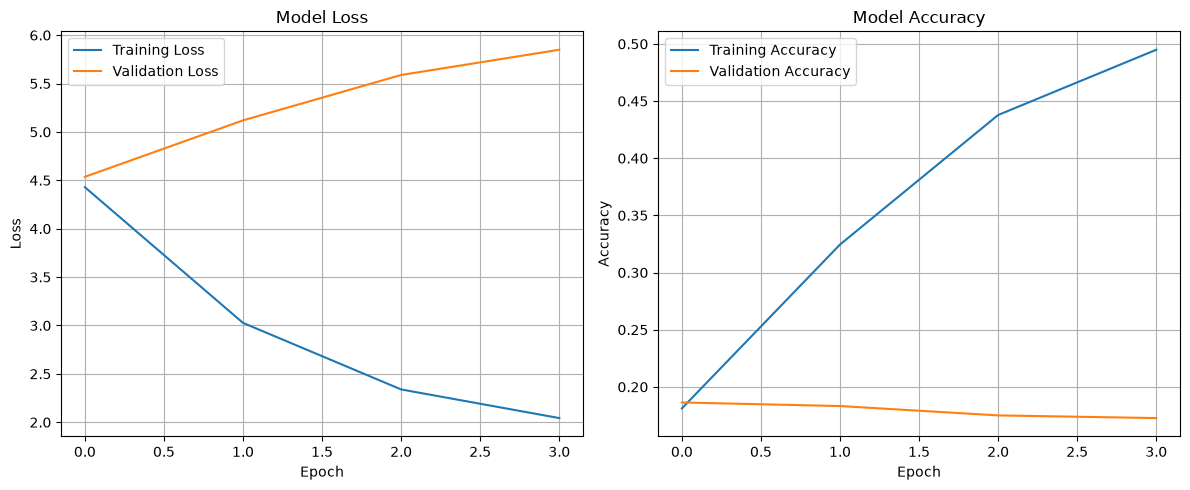

Best epoch: 1
loss: 4.4288
accuracy: 0.1812
val_loss: 4.5361
val_accuracy: 0.1863
Training time: 1897.47 seconds


In [42]:
# train
batch_size = 32
epochs = 30

start_time = time.perf_counter()

history_05 = model_clean_big.fit(
    train_inputs_clean, train_targets_clean,
    validation_data=(val_inputs_clean, val_targets_clean),
    batch_size=batch_size,
    epochs=epochs,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=3, restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(factor=0.5, patience=1),
        keras.callbacks.ModelCheckpoint('gutenberg_best_model_clean_big.keras', save_best_only=True)
    ]
)

training_time = time.perf_counter() - start_time

# plot training results
plot_training_metrics(history_05)

# save the model
model_clean_big.save('gutenberg_model_clean_big.keras')

# get the best epoch
best_epoch = int(np.argmin(history_05.history['val_loss']))
print(f"Best epoch: {best_epoch + 1}")

# print results
for key in ['loss', 'accuracy', 'val_loss', 'val_accuracy']:
    print(f"{key}: {history_05.history[key][best_epoch]:.4f}")

print(f"Training time: {training_time:.2f} seconds")

### Model comparison
Let's generate text with the models above and compare the results. We experiment with different temperatures: first 0.8 and then 1.0.

In [44]:
models_to_compare = {
    "Model 1 (clean)": (model_clean, sp_clean),
    "Model 2 (clean, dropout 0.3)": (model_clean_dropout03, sp_clean),
    "Model 3 (small)": (model_clean_small, sp_clean),
    "Model 4 (vocabulary 1000)": (model_clean_v1000, sp_v1000),
    "Model 5 (big)": (model_clean_big, sp_clean),
}

for name, (m, tokenizer) in models_to_compare.items():
    print(f"\n{name}")
    for prompt in prompts[:2]:
        np.random.seed(54)   # same seed for every model
        print(f"\nPrompt: {prompt}")
        print(generate_text(m, tokenizer, prompt, num_tokens=60, temperature=0.8))


Model 1 (clean)

Prompt: It was from the Carlton Club
It was from the Carlton Clubmouses. I's only no destrove. But why I have over, and coolling." "The relations here I't like an police." "The case that I have I felt that Holmes, Mrs. Gibson is such a bad offerline.

Prompt: Have you ever heard of Baron Gruner?
Have you ever heard of Baron Gruner? Dor man himself a pretty-cre from the Apartmind of her, and the seitful one of the paragenzrodde on the man between the strick-mering path, and affownwail, as a part that he

Model 2 (clean, dropout 0.3)

Prompt: It was from the Carlton Club
It was from the Carlton Clubs upon the last the cage, but as a brown pushed and fresh noticial! The man was a thing on the poisonle to-byrated vologistolore and but, with it, 'andy of your client, Mr. Holmes, with

Prompt: Have you ever heard of Baron Gruner?
Have you ever heard of Baron Gruner? Cam?" "You speaking all there was and in the body has known with a poor. The Gure of his little or it. He was

Next, we try with **temperature 1.0**.

In [45]:
# temperature 1.0
for name, (m, tokenizer) in models_to_compare.items():
    print(f"\n{name}")
    for prompt in prompts[:2]:
        np.random.seed(54)   # same seed for every model
        print(f"\nPrompt: {prompt}")
        print(generate_text(m, tokenizer, prompt, num_tokens=60, temperature=1.0))


Model 1 (clean)

Prompt: It was from the Carlton Club
It was from the Carlton Club speak and I am a pulled moved a way from the secretations. "What could! The alarble evening when he is secretary to-ted back. But he at the lady that I have be loose endct Professor, and sent a card. Now, the dogs for

Prompt: Have you ever heard of Baron Gruner?
Have you ever heard of Baron Gruner? But that I should the furnied where is a little more seldom seen. Sallery's palve never after an out. Watson was. "I hear it." "The two," he had is written at last. My face criminities were appearance to scene of

Model 2 (clean, dropout 0.3)

Prompt: It was from the Carlton Club
It was from the Carlton Clublikely and some sray character fiian main at the bloodened. "That mayp his no more for which is no otherh has wpanations. But you are you are elded in constating. How, I went you behind him, so I might did not

Prompt: Have you ever heard of Baron Gruner?
Have you ever heard of Baron Gruner? Oraidly a dau

<h2>5. Evaluation</h2>

 - Arvioidaan mallin todellinen onnistuminen.
 - Selvitetään, kuinka hyvin malli vastaa sille alun perin asetettuihin liiketoimintavaatimuksiin (business requirements).<br>
 - Ei katsota mallin suorituskykyä (tämä tehdään kappaleessa 4), vaan palataan takaisin kappaleeseen 1. ja millä tavalla saavutetut tulokset vertautuu alkuperäisiin tavoitteisiin.

<h2>6. Deployment</h2>

- Malli viedään käytäntöön (deployment).
- Tähän sisältyy tulosten viestiminen ja suositusten luominen siitä, miten mallia tulisi hyödyntää käytännössä tai mitä jatkotoimenpiteitä tulisi tehdä.